### Calibration Signal

In [2]:
from utils.calibration import CalibrationSignal

filepath ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:41:22_freq_11_325G_bw_2.0M_ts_1707176482.0819871_inrx0.dat'

center_freq_rx = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6
cal = CalibrationSignal(filepath, center_freq_rx, tx_freq, sample_rate) # creates an instance of CalibrationSignal. More details in utils/calibration.py 
ref_sig_idx = cal.get_all_refsigidx(ref_sig_thresh=20) 

### Centertone Detect

In [3]:
from utils.centertone import CenterTone
import numpy as np
import matplotlib.pyplot as plt

centertone_instance = CenterTone(filepath, sample_rate=2e6) # creates an instance of CenterTone. More details in utils/centertone.py
idx = centertone_instance.get_centertoneidxs(2**15, ref_sig_idx, thresh_multiplier=3)

File saved at /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/centertone/centertone_idx.pkl
read all samples in 60.82636380195618 seconds


### Clean Detected Centertone

In [5]:
# omit_freq = [[0, 1e4], [2e4, 4e4], [1.14e4, 1.16e4], [1.4730e4, 1.4754e4], [1.4944e4, 1.4946e4], [1.5860e4, 1.5910e4], [1.6380e4, 1.6530e4], [1.7729e4, 1.8339e4]]
omit_freq_2_5 = [[1.7916e4, 1.8303e4], [1.4700e4, 1.4800e4], [1.1400e4, 1.1500e4], [0,1e4], [2e4, 4e4], [15835, 15850]]
idx_clean = centertone_instance.remove_nonsatellite_centertones(omit_freq_2_5)

(22412, 6)
clean (16455, 6)


### Track Satellite Centertone

In [6]:
# 2_3
# period_starts = [5, 58, 155, 205, 390, 450]
# period_ends = [25, 97, 183, 230, 430, 500]
# 2_5
period_starts = [364, 640, 798, 866]
period_ends = [392, 710, 833, 880]
tracks, combined_tracks = centertone_instance.get_centertone_tracks(period_starts, period_ends) # use the get_centertone_tracks() method to get the tracks of the center tones
# # load idx_clean from .mat
# import scipy.io
# from utils.centertone import CenterTone
# idx_clean = scipy.io.loadmat('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_3/22:03:48/center_tone/center_tone_idx_clean.mat')
# # get values from first key
# idx_clean = idx_clean['centertone_arr_clean']
# # plot the center tones
# import numpy as np
# import matplotlib.pyplot as plt
# # plt.figure()
# # for i in range(len(idx_clean)):
# #     plt.plot(idx_clean[i][0], int(idx_clean[i][2]), 'o', color='red')
# filepath ='/home/ishani/LeoPNT/USRP_data/2_3/utctime_3Feb2024_22:03:48_freq_11_325G_bw_2.0M_ts_1706997828.7235794_inrx0.dat'
# centertone_instance = CenterTone(filepath, sample_rate=2e6) # creates an instance of CenterTone. More details in utils/centertone.py
# tracks, combined_tracks = centertone_instance.get_centertone_tracks(period_starts, period_ends, centertone_arr_clean=idx_clean) # use the get_centertone_tracks() method to get the tracks of the center tones

centertone_tracks saved at /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/centertone/sat_centertone_tracks.mat
centertone_combined_track saved at /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/centertone/sat_centertone_tracks_combined.mat


/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


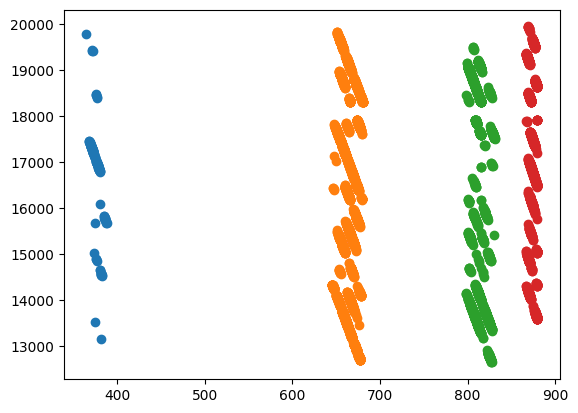

In [7]:
plt.figure()

for i in tracks.keys():
    plt.plot(tracks[i][:, 0], tracks[i][:, 2], 'o')
plt.show()

### Simulation

In [1]:
filepath ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:41:22_freq_11_325G_bw_2.0M_ts_1707176482.0819871_inrx0.dat'
ts = float(filepath.split('_')[-2])
print(ts)
# convert epoch time to datetime
import datetime
simulation_config = {}
simulation_config['start_time'] = ts
simulation_config['duration'] = 900

simulation_config['time_step'] = 1
satellite_config = {}
satellite_config['tle_file'] = '/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:41:14_starlink.tle'
satellite_config['min_elevation'] = 65

from utils.starlink_simulator import Simulation
sim = Simulation(filepath, simulation_config, satellite_config)
sats_dopp_dict = sim.get_dopp_tracks()

1707176482.0819871
Receiver config not specified. Using default values
number of Starlink satellites loaded 5407
Results related to simulation in:  /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/simulation_output
Current step:  2024-02-05 23:41:22+00:00
Current step:  2024-02-05 23:41:23+00:00
Current step:  2024-02-05 23:41:24+00:00
Current step:  2024-02-05 23:41:25+00:00
Current step:  2024-02-05 23:41:26+00:00
Current step:  2024-02-05 23:41:27+00:00
Current step:  2024-02-05 23:41:28+00:00
Current step:  2024-02-05 23:41:29+00:00
Current step:  2024-02-05 23:41:30+00:00
Current step:  2024-02-05 23:41:31+00:00
Current step:  2024-02-05 23:41:32+00:00
Current step:  2024-02-05 23:41:33+00:00
Current step:  2024-02-05 23:41:34+00:00
Current step:  2024-02-05 23:41:35+00:00
Current step:  2024-02-05 23:41:36+00:00
Current step:  2024-02-05 23:41:37+00:00
Current step:  2024-02-05 23:41:38+00:00
Current step:  2024-02-05 23:41:39+00:00
Current step:  2024-02-05 23:41:4

In [1]:
from utils.satellite_id import SatelliteID
filepath ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:41:22_freq_11_325G_bw_2.0M_ts_1707176482.0819871_inrx0.dat'
sat_id = SatelliteID(sim_dopp_tracks_matfile='/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/simulation_output/sim_dopp_tracks.mat', combined_centertone_tracks_matfile='/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/centertone/sat_centertone_tracks_combined.mat', file_path=filepath)
clean_combined_centertone_tracks = sat_id.get_clean_combined_centertone_tracks(sample_rate=2e6, nfft_centertone=2**15) # use the get_satellite_id() method to get the satellite id
print(clean_combined_centertone_tracks)
possible_sat_ids, matched_id = sat_id.match_simtrack_centertonetrack()
print(possible_sat_ids)
print(matched_id)

simulation track:  dict_keys(['STARLINK_3326', 'STARLINK_3558', 'STARLINK_5893', 'STARLINK_5845', 'STARLINK_30309', 'STARLINK_31014', 'STARLINK_6114', 'STARLINK_4159', 'STARLINK_30142', 'STARLINK_6248', 'STARLINK_1693', 'STARLINK_4165', 'STARLINK_1364', 'STARLINK_2654', 'STARLINK_5860', 'STARLINK_2533', 'STARLINK_4328', 'STARLINK_5111', 'STARLINK_4346', 'STARLINK_3311', 'STARLINK_3726', 'STARLINK_5906', 'STARLINK_6080', 'STARLINK_30762', 'STARLINK_4175', 'STARLINK_4323', 'STARLINK_30144', 'STARLINK_31063', 'STARLINK_31019', 'STARLINK_30830', 'STARLINK_1360', 'STARLINK_2620', 'STARLINK_4310', 'STARLINK_2550', 'STARLINK_5377', 'STARLINK_3308', 'STARLINK_6103', 'STARLINK_3738', 'STARLINK_30827', 'STARLINK_4306', 'STARLINK_5899', 'STARLINK_4182', 'STARLINK_30069', 'STARLINK_4284', 'STARLINK_5563', 'STARLINK_5847', 'STARLINK_4119', 'STARLINK_2703', 'STARLINK_4342', 'STARLINK_31041', 'STARLINK_31009', 'STARLINK_6030', 'STARLINK_4309', 'STARLINK_2740', 'STARLINK_30936'])
centertone track:  di

/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satellite_id.py:59: ComplexWarning: Casting complex values to real discards the imaginary part
  clean_track[i, 0] = time
/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satellite_id.py:60: ComplexWarning: Casting complex values to real discards the imaginary part
  clean_track[i, 1] = np.mean(track[idx, 2])
/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satellite_id.py:101: RankWarning: Polyfit may be poorly conditioned
  polynomial_coeff_sim_track = np.polyfit(sim_track[min(idx[0]):max(idx[0]), 1], sim_track[min(idx[0]):max(idx[0]), 2], 2)


{'STARLINK_3326': array([[ 1.70717648e+09,  0.00000000e+00, -9.83005252e+04,
         6.67077337e+01,  3.75536392e+01],
       [ 1.70717648e+09,  1.00000000e+00, -1.01003538e+05,
         6.60624600e+01,  3.79361565e+01],
       [ 1.70717648e+09,  2.00000000e+00, -1.03669875e+05,
         6.54218624e+01,  3.82966853e+01]]), 'STARLINK_3558': array([[ 1.70717648e+09,  0.00000000e+00, -2.56541634e+03,
         8.06657411e+01,  4.35023974e+01],
       [ 1.70717648e+09,  1.00000000e+00, -5.93610112e+03,
         8.05832004e+01,  4.81485001e+01],
       [ 1.70717648e+09,  2.00000000e+00, -9.30390719e+03,
         8.04411599e+01,  5.26836616e+01],
       [ 1.70717648e+09,  3.00000000e+00, -1.26671974e+04,
         8.02423846e+01,  5.70577317e+01],
       [ 1.70717649e+09,  4.00000000e+00, -1.60243454e+04,
         7.99904876e+01,  6.12314072e+01],
       [ 1.70717649e+09,  5.00000000e+00, -1.93737400e+04,
         7.96896561e+01,  6.51772573e+01],
       [ 1.70717649e+09,  6.00000000e+00, -2.

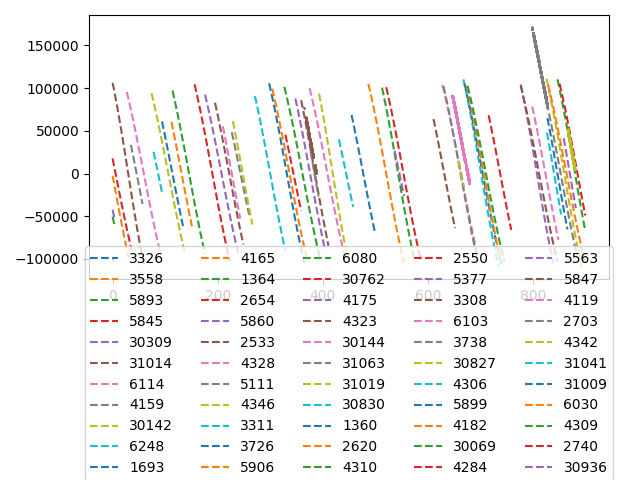

In [2]:
# load sim_dopp from .mat
import scipy.io as sio

sim_dopp = sio.loadmat('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/2_5/23:41:22/simulation_output/sim_dopp_tracks.mat')
sim_dopp.pop('__header__')
sim_dopp.pop('__version__')
sim_dopp.pop('__globals__')
# plot sim_dopp
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget
plt.figure()
plt.cla()
print(sim_dopp)
for sat in sim_dopp.keys():
    # if sat != 'STARLINK_4119':
    #     continue
    plt.plot(sim_dopp[sat][:,1], sim_dopp[sat][:,2], '--', label=sat.replace('STARLINK_', ''))
# # make legend two columns and place it outside below the plot and don't cut it off
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 0.15), ncol=5)
plt.tight_layout()
for sat in clean_combined_centertone_tracks.keys():
    plt.plot(clean_combined_centertone_tracks[sat][:,0], clean_combined_centertone_tracks[sat][:,1], 'o', markersize=1,label=sat)

In [ ]:
#TODO: implement matching of sim dopp tracks with center tone tracks
# make sure that the dopp tracks are correctly matched using screenshots